# Коллапс мод в GAN

Студент Камаев Сергей Михайлович, группа ИУ9-71Б.

Сравниваю обычный GAN с двумя лоссами и WGAN-GP на двух наборах, на кольце из 8 гауссиан и на сетке из 25 мод. Проверяю, где возникает коллапс и помогает ли с ним WGAN-GP.

Считаю на cpu в один поток, на четырёх потоках выходило медленнее. Минут пятнадцать на всё. Готовые картинки не подкладывал, всё обучается здесь, числа складываются в results/summary.json.

In [1]:
# окружение и параметры, два датасета и три бюджета шагов
import json
import os
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

%matplotlib inline
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.grid': True,
                     'grid.alpha': 0.25, 'axes.spines.top': False,
                     'axes.spines.right': False})

Z_DIM = 2
HIDDEN = 128
BATCH = 256

# два датасета, кольцо из 8 мод и сетка 25
DATASETS = {
    'ring8': dict(key='ring8', title='8 гауссиан по кругу', layout='ring', n_modes=8,
                  sigma=0.15, radius=2.0, metric_radius=0.4, share_min=0.05,
                  n_real=8000, out_scale=2.5),
    'grid25': dict(key='grid25', title='сетка 25 мод', layout='grid', n_modes=25,
                   sigma=0.07, step=1.05, metric_radius=0.3, share_min=0.015,
                   n_real=10000, out_scale=2.8),
}

STEPS_MAIN = 3000
STEPS_GRID = 4000
STEPS_LONG = 10000
SEEDS = (0, 1, 2)
SEEDS_GRID = (0, 1)

RUN_SKEW = True     # дисбаланс шагов дискриминатора
RUN_GRID = True     # сетка из 25 мод
RUN_LONG = True     # длинное обучение на 10 тыс шагов

LR = 1e-3
BETAS_GAN = (0.5, 0.999)
BETAS_WGAN = (0.5, 0.9)
N_CRITIC = 5
# штраф 1, а не 10, с десяткой критик слишком гладкий
LAMBDA_GP = 1.0

N_EVAL = 2000
SNAP_EVERY = 200
FIGS, RESULTS = 'figs', 'results'
os.makedirs(FIGS, exist_ok=True)
os.makedirs(RESULTS, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# один поток, на четырёх медленнее
torch.set_num_threads(1)


# центры мод, кольцо или квадратная сетка
def centers(spec):
    if spec['layout'] == 'ring':
        angles = 2 * np.pi * np.arange(spec['n_modes']) / spec['n_modes']
        return np.stack([spec['radius'] * np.cos(angles),
                         spec['radius'] * np.sin(angles)], axis=1)
    side = int(round(np.sqrt(spec['n_modes'])))
    xs = (np.arange(side) - (side - 1) / 2) * spec['step']
    return np.array([(x, y) for y in xs for x in xs], dtype=float)


for spec in DATASETS.values():
    spec['centers'] = centers(spec)

print(f'устройство {DEVICE} потоков {torch.get_num_threads()}')
for key, spec in DATASETS.items():
    print(f'{key}: {spec["n_modes"]} мод, сигма {spec["sigma"]}, '
          f'радиус засчитывания {spec["metric_radius"]}')

устройство cpu потоков 1
ring8: 8 мод, сигма 0.15, радиус засчитывания 0.4
grid25: 25 мод, сигма 0.07, радиус засчитывания 0.3


## Данные

Кольцо из 8 центров на окружности радиуса 2, шум 0.15, по 1000 точек на моду. Соседние центры стоят на 1.53, это десять сигм, моды не пересекаются.

Второй набор это сетка 5 на 5 с шагом 1.05, шум 0.07, по 400 точек на моду. Мод 25, и стоят они ближе, задача тяжелее.

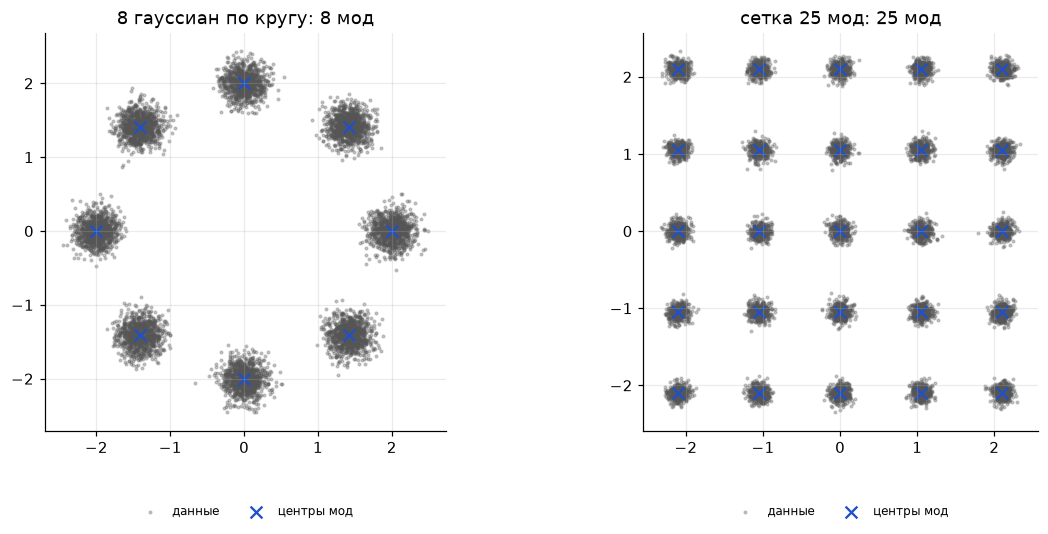

In [2]:
# обучающая выборка, точки вокруг центров
def sample_real(spec, seed=0):
    # доли мод одинаковые, иначе коллапс не отличить от дисбаланса данных
    rng = np.random.RandomState(seed)
    n = spec['n_real']
    labels = rng.permutation(np.arange(n) % spec['n_modes'])
    points = spec['centers'][labels] + rng.randn(n, 2) * spec['sigma']
    return points, labels


DATA = {key: sample_real(spec, seed=0) for key, spec in DATASETS.items()}

# один и тот же шум для всех контрольных снимков
Z_EVAL = torch.randn(N_EVAL, Z_DIM, generator=torch.Generator().manual_seed(1234)).to(DEVICE)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (key, spec) in zip(axes, DATASETS.items()):
    points, _ = DATA[key]
    ax.scatter(points[:, 0], points[:, 1], s=3, alpha=0.3, color='#555555', label='данные')
    c = spec['centers']
    ax.scatter(c[:, 0], c[:, 1], s=60, marker='x', color='#1f50c8', label='центры мод')
    ax.set_title(f'{spec["title"]}: {spec["n_modes"]} мод')
    ax.set_aspect('equal')
    ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.16),
              ncol=2, frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(FIGS, 'data.png'), dpi=160, bbox_inches='tight')
plt.show()

## Сети

Генератор 2 → 128 → 128 → 2, ReLU, tanh на выходе с масштабом 2.5, для сетки 2.8. Дискриминатор 2 → 128 → 128 → 1, LeakyReLU 0.2.

Сети во всех опытах одинаковые, по 17 тыс параметров. Разница между моделями только в функции потерь.

In [3]:
class Generator(nn.Module):
    # шум 2 -> 128 -> 128 -> точка, tanh держит выход в пределах данных
    def __init__(self, spec, hidden=HIDDEN):
        super().__init__()
        self.out_scale = spec['out_scale']
        self.net = nn.Sequential(
            nn.Linear(Z_DIM, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 2),
        )

    def forward(self, z):
        return self.out_scale * torch.tanh(self.net(z))


class Discriminator(nn.Module):
    # точка -> одно число, логит вероятности в gan или оценка критика в wgan
    def __init__(self, hidden=HIDDEN):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.net(x)


print(f'генератор {sum(p.numel() for p in Generator(DATASETS["ring8"]).parameters())} параметров')
print(f'дискриминатор {sum(p.numel() for p in Discriminator().parameters())} параметров')

генератор 17154 параметров
дискриминатор 17025 параметров


## Метрики

Мода покрыта, если в радиусе 0.4 от центра лежит хотя бы 5 процентов точек. Для кольца 0.4 это 2.7 сигмы, туда попадает 97 процентов настоящих точек. Для сетки радиус 0.3 и порог 1.5 процента, равномерная доля там 4 процента.

Ещё считаю долю точек в кластерах, максимальную долю одной моды, энтропию долей (единица значит равномерно, ноль значит всё в одной) и медианное расстояние до центра в сигмах. У настоящих данных медиана около 1.2, больше значит точки размазаны.

Коллапсом на кольце считаю покрытие меньше 6 мод из 8 или долю крупнейшей моды больше 0.35. Порог выбрал до прогона, чтобы не подгонять его под результат.

In [4]:
# метрики покрытия, доли в кластерах, энтропии и резкости
def mode_stats(points, spec, radius=None, share_min=None):
    centers_ = spec['centers']
    radius = spec['metric_radius'] if radius is None else radius
    share_min = spec['share_min'] if share_min is None else share_min

    d = np.linalg.norm(points[:, None, :] - centers_[None, :, :], axis=2)
    nearest = d.argmin(axis=1)
    dist = d[np.arange(len(points)), nearest]
    inside = dist < radius
    shares = np.bincount(nearest[inside], minlength=len(centers_)) / len(points)

    prob = shares[shares > 0]
    entropy = float(-(prob * np.log(prob)).sum() / np.log(len(centers_)))
    return {'covered': int((shares >= share_min).sum()),
            'in_cluster': float(inside.mean()),
            'shares': shares,
            'max_share': float(shares.max()),
            'entropy': entropy,
            'sharp': float(np.median(dist) / spec['sigma'])}


@torch.no_grad()
def draw(G, z=Z_EVAL):
    # точки генератора на фиксированном шуме
    return G(z).cpu().numpy()


# контрольный снимок метрик и точек
def record(hist, snaps, G, spec, step, loss_d, loss_g, verbose):
    points = draw(G)
    st = mode_stats(points, spec)
    for key in ('covered', 'in_cluster', 'max_share', 'entropy', 'sharp'):
        hist[key].append(st[key])
    hist['step'].append(step)
    hist['shares'].append(st['shares'])
    hist['d_loss'].append(loss_d.detach().item())
    hist['g_loss'].append(loss_g.detach().item())
    snaps[step] = points
    if verbose:
        print(f'  шаг {step:5d} мод {st["covered"]} из {spec["n_modes"]} '
              f'в кластерах {100 * st["in_cluster"]:4.0f} % '
              f'd {hist["d_loss"][-1]:.2f} g {hist["g_loss"][-1]:.2f}')


# пустая история для нового запуска
def empty_hist():
    return {key: [] for key in ('step', 'covered', 'in_cluster', 'max_share',
                                'entropy', 'sharp', 'shares', 'd_loss', 'g_loss')}

In [5]:
# шум метрики, две независимые выборки настоящих данных
floor = []
for seed in (1, 2):
    points, _ = sample_real(DATASETS['ring8'], seed=seed)
    st = mode_stats(points, DATASETS['ring8'])
    floor.append({'выборка': seed,
                  'покрыто мод': st['covered'],
                  'в кластерах, %': round(100 * st['in_cluster'], 1),
                  'энтропия': round(st['entropy'], 3),
                  'резкость, сигм': round(st['sharp'], 2)})

display(pd.DataFrame(floor))

,выборка,покрыто мод,"в кластерах, %",энтропия,"резкость, сигм"
0,1,8,97.3,0.986,1.19
1,2,8,97.0,0.984,1.17


## Обычный GAN и два лосса

В статье генератор минимизирует log(1 − D(G(z))), в коде берут минус log D(G(z)). У первого градиент пропадает, когда дискриминатор уверен. Проверяю оба варианта.

$ \min_G \max_D E_(x ~ p_"data") log D(x) + E_(z ~ p_z) log(1 - D(G(z))) $

Минимаксное плечо сначала стояло на месте, я хотел его убрать. Оставил как контрольную точку.

In [6]:
# обычный gan, nonsat как в практике, minimax как в статье
def train_gan(spec, seed=0, steps=STEPS_MAIN, loss='nonsat', lr_g=LR, lr_d=LR, verbose=True):
    torch.manual_seed(seed)
    rng = np.random.RandomState(seed)
    x_real = torch.tensor(sample_real(spec, seed)[0], dtype=torch.float32, device=DEVICE)
    G, D = Generator(spec).to(DEVICE), Discriminator().to(DEVICE)
    opt_g = torch.optim.Adam(G.parameters(), lr=lr_g, betas=BETAS_GAN)
    opt_d = torch.optim.Adam(D.parameters(), lr=lr_d, betas=BETAS_GAN)
    bce = nn.BCEWithLogitsLoss()
    ones = torch.ones(BATCH, 1, device=DEVICE)
    zeros = torch.zeros(BATCH, 1, device=DEVICE)

    hist, snaps = empty_hist(), {}
    target_g = zeros if loss == 'minimax' else ones
    t0 = time.time()

    for step in range(steps + 1):
        idx = rng.randint(0, len(x_real), size=BATCH)
        x = x_real[idx]
        loss_d = bce(D(torch.cat([x, G(torch.randn(BATCH, Z_DIM, device=DEVICE)).detach()])),
                     torch.cat([ones, zeros]))
        opt_d.zero_grad()
        loss_d.backward()
        opt_d.step()

        loss_g = bce(D(G(torch.randn(BATCH, Z_DIM, device=DEVICE))), target_g)
        opt_g.zero_grad()
        loss_g.backward()
        opt_g.step()

        if step % SNAP_EVERY == 0:
            record(hist, snaps, G, spec, step, loss_d, loss_g, verbose)

    spent = time.time() - t0
    name = 'GAN-минимакс' if loss == 'minimax' else 'GAN'
    if verbose:
        print(f'{name} на {spec["title"]}: {spent:.0f} c')
    return {'dataset': spec['key'], 'model': name, 'seed': seed, 'steps': steps,
            'gen': G, 'hist': hist, 'snaps': snaps, 'time': spent}

## WGAN-GP

Вместо дискриминатора критик. Он оценивает расстояние землекопа и должен быть 1-липшицевым. Держу это штрафом за норму градиента, критик обновляю 5 раз на шаг генератора.

$ W_1(p, q) = sup_f ( E_(x ~ p) f(x) - E_(x ~ q) f(x) ) $

Штраф 1, а не 10 как в статье. С десяткой критик слишком гладкий, и точки ложатся кольцом между модами.

In [7]:
# штраф за норму градиента критика
def gradient_penalty(D, real, fake):
    alpha = torch.rand(len(real), 1, device=DEVICE)
    mixed = (alpha * real + (1 - alpha) * fake).requires_grad_(True)
    out = D(mixed)
    grad = torch.autograd.grad(out.sum(), mixed, create_graph=True)[0]
    return ((grad.norm(2, dim=1) - 1) ** 2).mean()


# wgan-gp, критик обновляется 5 раз на шаг генератора
def train_wgan(spec, seed=0, steps=STEPS_MAIN, verbose=True):
    torch.manual_seed(seed)
    rng = np.random.RandomState(seed)
    x_real = torch.tensor(sample_real(spec, seed)[0], dtype=torch.float32, device=DEVICE)
    G, D = Generator(spec).to(DEVICE), Discriminator().to(DEVICE)
    opt_g = torch.optim.Adam(G.parameters(), lr=LR, betas=BETAS_WGAN)
    opt_d = torch.optim.Adam(D.parameters(), lr=LR, betas=BETAS_WGAN)

    hist, snaps = empty_hist(), {}
    t0 = time.time()

    for step in range(steps + 1):
        for _ in range(N_CRITIC):
            idx = rng.randint(0, len(x_real), size=BATCH)
            x = x_real[idx]
            with torch.no_grad():
                fake = G(torch.randn(BATCH, Z_DIM, device=DEVICE))
            loss_d = D(fake).mean() - D(x).mean() + LAMBDA_GP * gradient_penalty(D, x, fake)
            opt_d.zero_grad()
            loss_d.backward()
            opt_d.step()

        loss_g = -D(G(torch.randn(BATCH, Z_DIM, device=DEVICE))).mean()
        opt_g.zero_grad()
        loss_g.backward()
        opt_g.step()

        if step % SNAP_EVERY == 0:
            record(hist, snaps, G, spec, step, loss_d, loss_g, verbose)

    spent = time.time() - t0
    if verbose:
        print(f'WGAN-GP на {spec["title"]}: {spent:.0f} c')
    return {'dataset': spec['key'], 'model': 'WGAN-GP', 'seed': seed, 'steps': steps,
            'gen': G, 'hist': hist, 'snaps': snaps, 'time': spent}

## Прогон на кольце

Три модели, три сида, условия одинаковые. Минимаксный GAN рядом как контрольная точка.

In [8]:
runs = {'ring8': {'GAN': [], 'WGAN-GP': [], 'GAN-минимакс': []}, 'grid25': {'GAN': [], 'WGAN-GP': []}}

for seed in SEEDS:
    runs['ring8']['GAN'].append(train_gan(DATASETS['ring8'], seed=seed, loss='nonsat', verbose=seed == 0))
    runs['ring8']['WGAN-GP'].append(train_wgan(DATASETS['ring8'], seed=seed, verbose=seed == 0))
    runs['ring8']['GAN-минимакс'].append(train_gan(DATASETS['ring8'], seed=seed, loss='minimax', verbose=False))


# одна строка таблицы по запуску
def flat_row(res):
    spec = DATASETS[res['dataset']]
    st = mode_stats(draw(res['gen']), spec)
    cover = res['hist']['covered'][1:]
    return {'датасет': spec['title'], 'модель': res['model'], 'сид': res['seed'],
            'шагов': res['steps'],
            'покрыто мод': st['covered'],
            'среднее покрытие': round(float(np.mean(cover)), 1),
            'в кластерах, %': round(100 * st['in_cluster'], 1),
            'макс. доля, %': round(100 * st['max_share'], 1),
            'энтропия': round(st['entropy'], 3),
            'резкость, сигм': round(st['sharp'], 2),
            'время, с': round(res['time'])}


data_row = mode_stats(DATA['ring8'][0], DATASETS['ring8'])
rows = [{'датасет': DATASETS['ring8']['title'], 'модель': 'данные', 'сид': '—', 'шагов': '—',
         'покрыто мод': data_row['covered'], 'среднее покрытие': '—',
         'в кластерах, %': round(100 * data_row['in_cluster'], 1),
         'макс. доля, %': round(100 * data_row['max_share'], 1),
         'энтропия': round(data_row['entropy'], 3),
         'резкость, сигм': round(data_row['sharp'], 2), 'время, с': '—'}]
rows += [flat_row(res) for model in runs['ring8'] for res in runs['ring8'][model]]
display(pd.DataFrame(rows))

  шаг     0 мод 0 из 8 в кластерах    0 % d 0.69 g 0.72
  шаг   200 мод 1 из 8 в кластерах   33 % d 0.63 g 1.37
  шаг   400 мод 1 из 8 в кластерах   33 % d 0.74 g 0.74
  шаг   600 мод 0 из 8 в кластерах    7 % d 0.78 g 0.54
  шаг   800 мод 1 из 8 в кластерах   20 % d 0.69 g 0.77
  шаг  1000 мод 0 из 8 в кластерах   17 % d 0.68 g 0.73
  шаг  1200 мод 2 из 8 в кластерах   27 % d 0.68 g 0.70
  шаг  1400 мод 3 из 8 в кластерах   45 % d 0.68 g 0.71
  шаг  1600 мод 6 из 8 в кластерах   53 % d 0.67 g 0.72
  шаг  1800 мод 8 из 8 в кластерах   70 % d 0.67 g 0.70
  шаг  2000 мод 8 из 8 в кластерах   70 % d 0.67 g 0.74
  шаг  2200 мод 8 из 8 в кластерах   78 % d 0.67 g 0.72
  шаг  2400 мод 8 из 8 в кластерах   82 % d 0.67 g 0.72
  шаг  2600 мод 8 из 8 в кластерах   84 % d 0.68 g 0.71
  шаг  2800 мод 8 из 8 в кластерах   83 % d 0.68 g 0.73
  шаг  3000 мод 8 из 8 в кластерах   87 % d 0.69 g 0.73
GAN на 8 гауссиан по кругу: 17 c
  шаг     0 мод 0 из 8 в кластерах    0 % d -0.06 g 0.16
  шаг   200 мо

,датасет,модель,сид,шагов,покрыто мод,среднее покрытие,"в кластерах, %","макс. доля, %",энтропия,"резкость, сигм","время, с"
0,8 гауссиан по кругу,данные,—,—,8,—,97.2,12.3,0.985,1.17,—
1,8 гауссиан по кругу,GAN,0,3000,8,4.7,87.0,13.1,0.925,0.94,17
2,8 гауссиан по кругу,GAN,1,3000,8,6.3,84.9,13.1,0.913,1.08,17
3,8 гауссиан по кругу,GAN,2,3000,8,7.8,93.0,13.4,0.961,0.89,17
4,8 гауссиан по кругу,WGAN-GP,0,3000,8,7.8,89.8,13.9,0.942,0.78,90
5,8 гауссиан по кругу,WGAN-GP,1,3000,8,7.9,89.5,12.3,0.941,1.12,87
6,8 гауссиан по кругу,WGAN-GP,2,3000,8,7.7,88.4,12.2,0.936,1.02,86
7,8 гауссиан по кругу,GAN-минимакс,0,3000,0,0.0,0.0,0.0,-0.000,10.24,17
8,8 гауссиан по кругу,GAN-минимакс,1,3000,0,0.0,0.0,0.0,-0.000,10.23,17
9,8 гауссиан по кругу,GAN-минимакс,2,3000,0,0.0,0.0,0.0,-0.000,10.23,16


## Картинки

Динамика по шагам, облака после обучения, тепловая карта долей и кривые покрытия. Всё сохраняется в figs/.

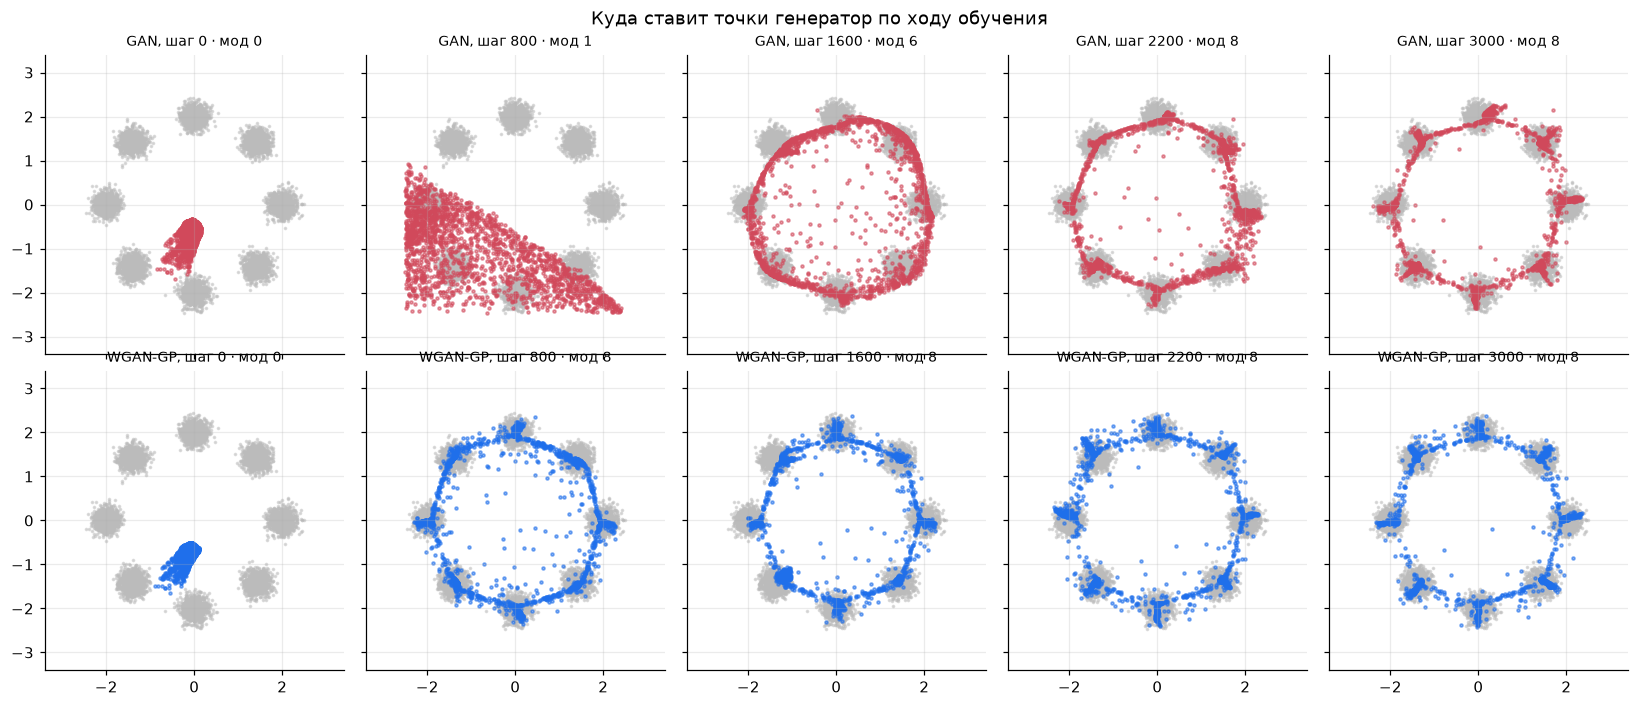

In [9]:
# динамика, сверху обычный gan, снизу wgan-gp, шаги выбираются равномерно
def pick_steps(hist, n=5):
    idx = np.linspace(0, len(hist['step']) - 1, n).round().astype(int)
    return [hist['step'][i] for i in idx]


gan8 = runs['ring8']['GAN'][0]
wgan8 = runs['ring8']['WGAN-GP'][0]
steps_show = pick_steps(gan8['hist'])
spec8 = DATASETS['ring8']

fig, axes = plt.subplots(2, len(steps_show), figsize=(15, 6.4), sharex=True, sharey=True)
for row, (res, color) in enumerate(((gan8, '#d1495b'), (wgan8, '#1f6feb'))):
    for col, step in enumerate(steps_show):
        ax = axes[row, col]
        ax.scatter(DATA['ring8'][0][:, 0], DATA['ring8'][0][:, 1], s=2, color='#bbbbbb', alpha=0.45)
        points = res['snaps'][step]
        ax.scatter(points[:, 0], points[:, 1], s=4, color=color, alpha=0.55)
        st = mode_stats(points, spec8)
        ax.set_title(f'{res["model"]}, шаг {step} · мод {st["covered"]}', fontsize=9)
        ax.set_xlim(-3.4, 3.4)
        ax.set_ylim(-3.4, 3.4)
        ax.set_aspect('equal')
fig.suptitle('Куда ставит точки генератор по ходу обучения', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(FIGS, 'snapshots.png'), dpi=150, bbox_inches='tight')
plt.show()

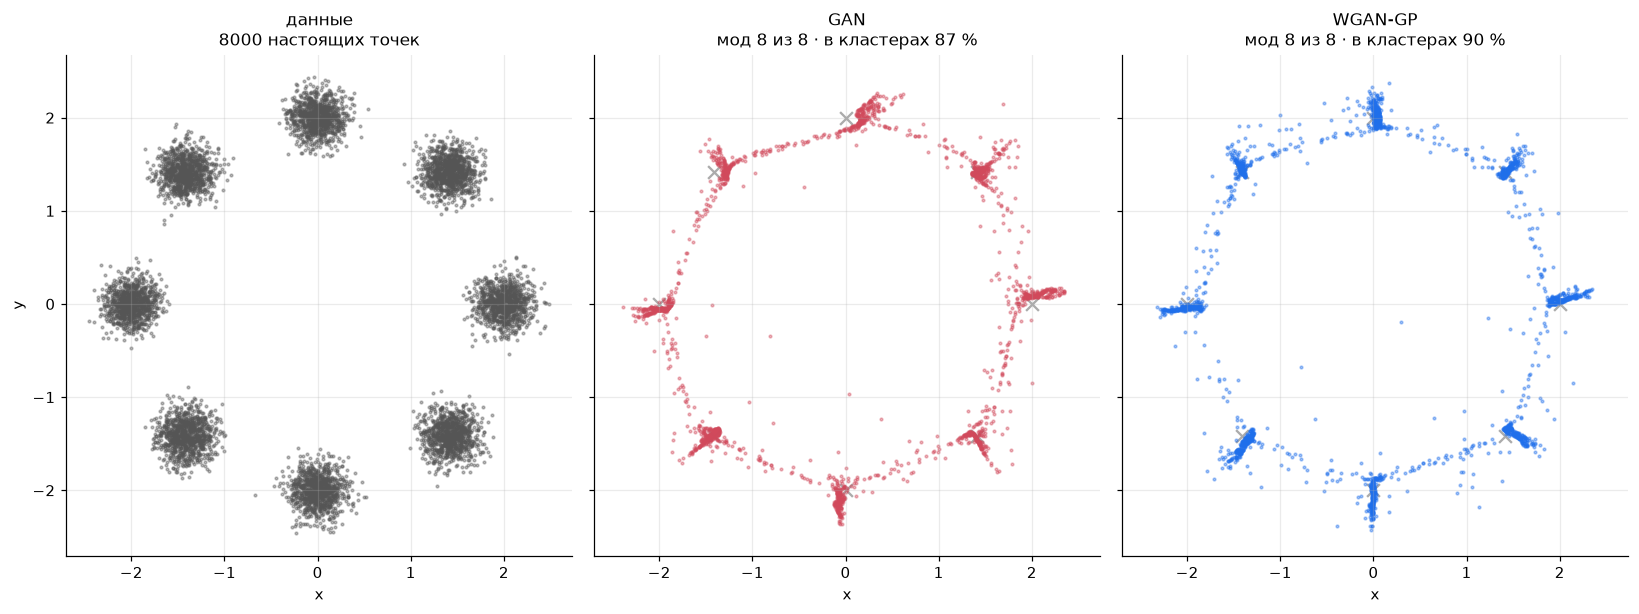

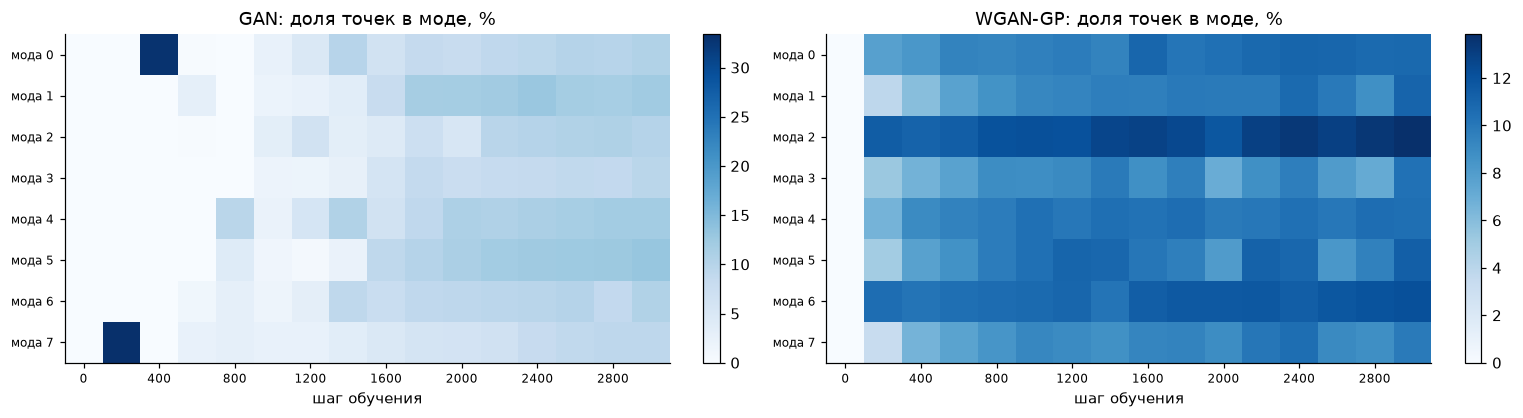

In [10]:
# итоговые облака и тепловая карта долей по модам
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharex=True, sharey=True)
panels = [('данные', DATA['ring8'][0], '#555555'),
          ('GAN', draw(gan8['gen']), '#d1495b'),
          ('WGAN-GP', draw(wgan8['gen']), '#1f6feb')]
for ax, (name, points, color) in zip(axes, panels):
    ax.scatter(spec8['centers'][:, 0], spec8['centers'][:, 1], s=70, marker='x',
               color='#888888', alpha=0.7)
    ax.scatter(points[:, 0], points[:, 1], s=3, color=color, alpha=0.4)
    if name == 'данные':
        subtitle = f'{len(points)} настоящих точек'
    else:
        st = mode_stats(points, spec8)
        subtitle = f'мод {st["covered"]} из 8 · в кластерах {100 * st["in_cluster"]:.0f} %'
    ax.set_title(f'{name}\n{subtitle}', fontsize=11)
    ax.set_xlabel('x')
    ax.set_aspect('equal')
axes[0].set_ylabel('y')
plt.tight_layout()
plt.savefig(os.path.join(FIGS, 'final.png'), dpi=150, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 3.9))
for ax, res in zip(axes, (gan8, wgan8)):
    mat = np.array(res['hist']['shares']).T * 100
    im = ax.imshow(mat, aspect='auto', cmap='Blues', vmin=0)
    ax.set_yticks(range(8))
    ax.set_yticklabels([f'мода {i}' for i in range(8)], fontsize=8)
    ticks = res['hist']['step']
    keep = list(range(0, len(ticks), max(1, len(ticks) // 6)))
    ax.set_xticks(keep)
    ax.set_xticklabels([ticks[i] for i in keep], fontsize=8)
    ax.set_xlabel('шаг обучения')
    ax.set_title(f'{res["model"]}: доля точек в моде, %')
    ax.grid(False)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(os.path.join(FIGS, 'mode_share.png'), dpi=150, bbox_inches='tight')
plt.show()

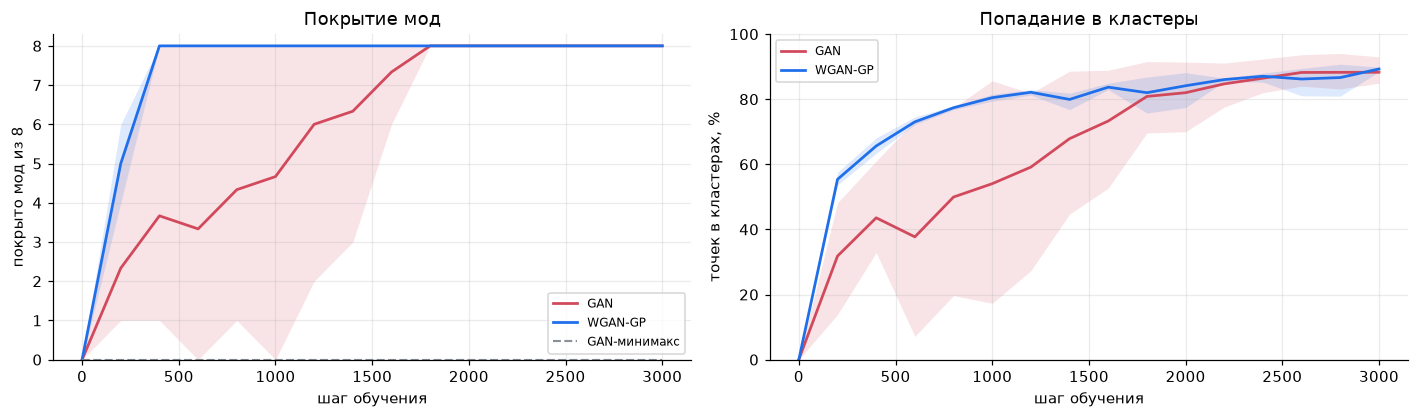

In [11]:
# покрытие и попадание в кластеры по шагам, среднее по сидам и разброс
colors = {'GAN': '#d1495b', 'WGAN-GP': '#1f6feb', 'GAN-минимакс': '#8a8f98'}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for name in ('GAN', 'WGAN-GP'):
    hist_list = [res['hist'] for res in runs['ring8'][name]]
    steps_ = hist_list[0]['step']
    covered = np.array([h['covered'] for h in hist_list])
    inside = np.array([[100 * v for v in h['in_cluster']] for h in hist_list])
    axes[0].plot(steps_, covered.mean(0), '-', color=colors[name], lw=1.8, label=name)
    axes[0].fill_between(steps_, covered.min(0), covered.max(0), color=colors[name], alpha=0.15, lw=0)
    axes[1].plot(steps_, inside.mean(0), '-', color=colors[name], lw=1.8, label=name)
    axes[1].fill_between(steps_, inside.min(0), inside.max(0), color=colors[name], alpha=0.15, lw=0)
axes[0].plot(runs['ring8']['GAN-минимакс'][0]['hist']['step'],
             runs['ring8']['GAN-минимакс'][0]['hist']['covered'], '--',
             color=colors['GAN-минимакс'], lw=1.4, label='GAN-минимакс')
axes[0].set_ylim(0, 8.3)
axes[0].set_ylabel('покрыто мод из 8')
axes[1].set_ylim(0, 100)
axes[1].set_ylabel('точек в кластерах, %')
for ax, title in zip(axes, ('Покрытие мод', 'Попадание в кластеры')):
    ax.set_xlabel('шаг обучения')
    ax.set_title(title)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIGS, 'curves.png'), dpi=150, bbox_inches='tight')
plt.show()

## Дисбаланс шагов

Тот же GAN, но шаг дискриминатора в тридцать раз больше, 3e-3 против 1e-4. Дискриминатор учится быстрее и перестаёт пропускать редкие моды.

Два сида, чтобы отличить эффект от инициализации.

In [12]:
skew = []
# дисбаланс шагов, у дискриминатора шаг в 30 раз больше
if RUN_SKEW:
    for seed in (0, 1):
        res = train_gan(DATASETS['ring8'], seed=seed, loss='nonsat',
                        lr_g=1e-4, lr_d=3e-3, verbose=False)
        st = mode_stats(draw(res['gen']), DATASETS['ring8'])
        skew.append({'сид': seed, 'покрыто мод': st['covered'],
                     'в кластерах, %': round(100 * st['in_cluster'], 1),
                     'макс. доля, %': round(100 * st['max_share'], 1)})
        print(f'сид {seed}: мод {st["covered"]} из 8, в кластерах {100 * st["in_cluster"]:.0f} %')
    display(pd.DataFrame(skew))

сид 0: мод 4 из 8, в кластерах 81 %
сид 1: мод 4 из 8, в кластерах 76 %


,сид,покрыто мод,"в кластерах, %","макс. доля, %"
0,0,4,81.0,19.8
1,1,4,76.3,23.2


## Сетка 25 мод

Та же пара моделей на сетке. Проверяю, остаётся ли преимущество WGAN-GP, когда мод много и они близко.

Два сида, дальше не стал. Один прогон WGAN-GP идёт чуть больше минуты.

  шаг     0 мод 1 из 25 в кластерах   10 % d 0.69 g 0.73
  шаг   200 мод 6 из 25 в кластерах   22 % d 0.70 g 0.72
  шаг   400 мод 6 из 25 в кластерах   25 % d 0.70 g 0.66
  шаг   600 мод 4 из 25 в кластерах   26 % d 0.69 g 0.70
  шаг   800 мод 6 из 25 в кластерах   27 % d 0.69 g 0.70
  шаг  1000 мод 3 из 25 в кластерах   27 % d 0.69 g 0.70
  шаг  1200 мод 4 из 25 в кластерах   28 % d 0.69 g 0.68
  шаг  1400 мод 1 из 25 в кластерах   27 % d 0.69 g 0.70
  шаг  1600 мод 1 из 25 в кластерах   26 % d 0.69 g 0.71
  шаг  1800 мод 3 из 25 в кластерах   26 % d 0.69 g 0.69
  шаг  2000 мод 7 из 25 в кластерах   30 % d 0.69 g 0.69
  шаг  2200 мод 5 из 25 в кластерах   29 % d 0.69 g 0.72
  шаг  2400 мод 8 из 25 в кластерах   34 % d 0.68 g 0.73
  шаг  2600 мод 13 из 25 в кластерах   39 % d 0.68 g 0.69
  шаг  2800 мод 16 из 25 в кластерах   42 % d 0.67 g 0.79
  шаг  3000 мод 14 из 25 в кластерах   43 % d 0.67 g 0.69
  шаг  3200 мод 17 из 25 в кластерах   49 % d 0.67 g 0.71
  шаг  3400 мод 20 из 25 в 

,датасет,модель,сид,шагов,покрыто мод,среднее покрытие,"в кластерах, %","макс. доля, %",энтропия,"резкость, сигм","время, с"
0,сетка 25 мод,GAN,0,4000,20,9.7,59.2,3.7,0.676,3.58,22
1,сетка 25 мод,GAN,1,4000,24,11.0,66.2,4.4,0.737,3.11,23
2,сетка 25 мод,WGAN-GP,0,4000,15,10.8,41.3,3.0,0.517,4.88,112
3,сетка 25 мод,WGAN-GP,1,4000,25,16.4,86.1,4.7,0.897,0.95,117


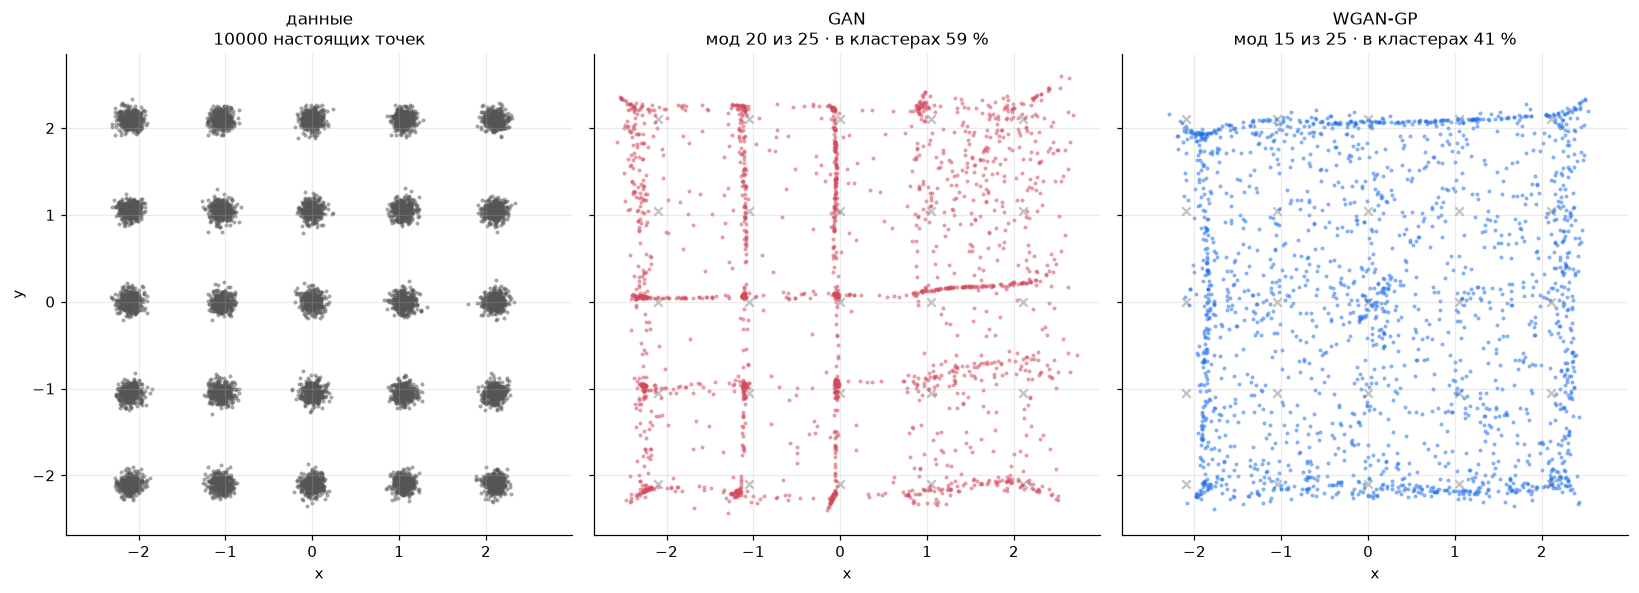

In [13]:
# сетка 25 мод, та же пара моделей на тяжёлом датасете
if RUN_GRID:
    for seed in SEEDS_GRID:
        runs['grid25']['GAN'].append(train_gan(DATASETS['grid25'], seed=seed,
                                              steps=STEPS_GRID, verbose=seed == 0))
        runs['grid25']['WGAN-GP'].append(train_wgan(DATASETS['grid25'], seed=seed,
                                                    steps=STEPS_GRID, verbose=False))

    rows = [flat_row(res) for model in runs['grid25'] for res in runs['grid25'][model]]
    display(pd.DataFrame(rows))

    spec25 = DATASETS['grid25']
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharex=True, sharey=True)
    panels = [('данные', DATA['grid25'][0], '#555555'),
              ('GAN', draw(runs['grid25']['GAN'][0]['gen']), '#d1495b'),
              ('WGAN-GP', draw(runs['grid25']['WGAN-GP'][0]['gen']), '#1f6feb')]
    for ax, (name, points, color) in zip(axes, panels):
        ax.scatter(spec25['centers'][:, 0], spec25['centers'][:, 1], s=30, marker='x',
                   color='#888888', alpha=0.5)
        ax.scatter(points[:, 0], points[:, 1], s=3, color=color, alpha=0.4)
        if name == 'данные':
            subtitle = f'{len(points)} настоящих точек'
        else:
            st = mode_stats(points, spec25)
            subtitle = f'мод {st["covered"]} из 25 · в кластерах {100 * st["in_cluster"]:.0f} %'
        ax.set_title(f'{name}\n{subtitle}', fontsize=11)
        ax.set_aspect('equal')
        ax.set_xlabel('x')
    axes[0].set_ylabel('y')
    plt.tight_layout()
    plt.savefig(os.path.join(FIGS, 'grid25.png'), dpi=150, bbox_inches='tight')
    plt.show()

## Длинное обучение

10 тыс шагов, один сид. Смотрю, не разваливается ли WGAN-GP и не теряет ли моды GAN после выхода из коллапса.

Теряет WGAN-GP. Кластеры расплываются, одну моду он упускает.

,датасет,модель,сид,шагов,покрыто мод,среднее покрытие,"в кластерах, %","макс. доля, %",энтропия,"резкость, сигм","время, с"
0,8 гауссиан по кругу,GAN,0,10000,8,7.0,97.4,13.8,0.984,1.13,52
1,8 гауссиан по кругу,WGAN-GP,0,10000,7,7.8,66.2,11.3,0.781,2.18,286


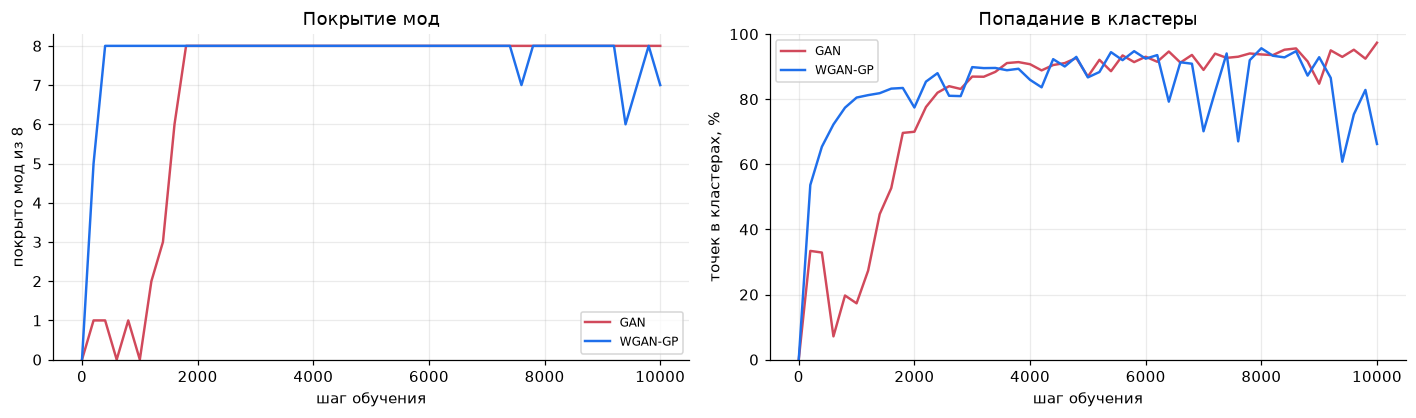

In [14]:
long_res = {}
# длинное обучение, 10 тыс шагов, один сид
if RUN_LONG:
    long_res['GAN'] = train_gan(DATASETS['ring8'], seed=0, steps=STEPS_LONG, verbose=False)
    long_res['WGAN-GP'] = train_wgan(DATASETS['ring8'], seed=0, steps=STEPS_LONG, verbose=False)

    rows = [flat_row(res) for res in long_res.values()]
    display(pd.DataFrame(rows))

    fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
    for name, res in long_res.items():
        hist = res['hist']
        axes[0].plot(hist['step'], hist['covered'], '-', color=colors[name], lw=1.6, label=name)
        axes[1].plot(hist['step'], [100 * v for v in hist['in_cluster']], '-',
                     color=colors[name], lw=1.6, label=name)
    axes[0].set_ylim(0, 8.3)
    axes[0].set_ylabel('покрыто мод из 8')
    axes[1].set_ylim(0, 100)
    axes[1].set_ylabel('точек в кластерах, %')
    for ax, title in zip(axes, ('Покрытие мод', 'Попадание в кластеры')):
        ax.set_xlabel('шаг обучения')
        ax.set_title(title)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGS, 'long.png'), dpi=150, bbox_inches='tight')
    plt.show()

## Сводка

Числа по всем запускам складываю в results/summary.json.

In [15]:
# сводка по модели для json
def group_stats(dataset, model):
    part = [flat_row(res) for res in runs[dataset][model]]
    frame = pd.DataFrame(part)
    return {'runs': part,
            'modes_mean': float(frame['покрыто мод'].mean()),
            'modes_min': int(frame['покрыто мод'].min()),
            'modes_max': int(frame['покрыто мод'].max()),
            'cover_avg': float(frame['среднее покрытие'].mean()),
            'in_mean': float(frame['в кластерах, %'].mean()),
            'max_share_mean': float(frame['макс. доля, %'].mean()),
            'entropy_mean': float(frame['энтропия'].mean()),
            'sharp_mean': float(frame['резкость, сигм'].mean()),
            'time_mean': float(frame['время, с'].mean())}


groups = {}
for dataset in ('ring8', 'grid25'):
    for model in runs[dataset]:
        if not runs[dataset][model]:
            continue
        groups[f'{dataset}|{model}'] = group_stats(dataset, model)

summary = {'config': {'steps_main': STEPS_MAIN, 'steps_grid': STEPS_GRID,
                      'steps_long': STEPS_LONG, 'seeds': list(SEEDS),
                      'seeds_grid': list(SEEDS_GRID), 'batch': BATCH,
                      'lr': LR, 'n_critic': N_CRITIC, 'lambda_gp': LAMBDA_GP},
           'datasets': {key: {k: v for k, v in spec.items() if k != 'centers'}
                        for key, spec in DATASETS.items()},
           'skew': skew,
           'groups': groups}
if long_res:
    summary['long'] = {name: flat_row(res) for name, res in long_res.items()}

with open(os.path.join(RESULTS, 'summary.json'), 'w', encoding='utf-8') as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

print(f'сохранено {os.path.join(RESULTS, "summary.json")}')
print()
for key, value in groups.items():
    if key.startswith('ring8'):
        print(f'{key:22s} мод {value["modes_mean"]:.1f} из 8, '
              f'среднее {value["cover_avg"]:.1f}, в кластерах {value["in_mean"]:.0f} %, '
              f'энтропия {value["entropy_mean"]:.2f}, резкость {value["sharp_mean"]:.2f} сигм')
    if key.startswith('grid25'):
        print(f'{key:22s} мод {value["modes_mean"]:.1f} из 25, '
              f'в кластерах {value["in_mean"]:.0f} %')
if long_res:
    for name, res in long_res.items():
        row = flat_row(res)
        print(f'10k {name:9s} мод {row["покрыто мод"]} из 8, '
              f'в кластерах {row["в кластерах, %"]} %')

сохранено results\summary.json

ring8|GAN              мод 8.0 из 8, среднее 6.3, в кластерах 88 %, энтропия 0.93, резкость 0.97 сигм
ring8|WGAN-GP          мод 8.0 из 8, среднее 7.8, в кластерах 89 %, энтропия 0.94, резкость 0.97 сигм
ring8|GAN-минимакс     мод 0.0 из 8, среднее 0.0, в кластерах 0 %, энтропия 0.00, резкость 10.23 сигм
grid25|GAN             мод 22.0 из 25, в кластерах 63 %
grid25|WGAN-GP         мод 20.0 из 25, в кластерах 64 %
10k GAN       мод 8 из 8, в кластерах 97.4 %
10k WGAN-GP   мод 7 из 8, в кластерах 66.2 %


## Выводы

1. Я ожидал коллапс на кольце, но при равных условиях обе модели к концу покрывают все восемь мод. GAN просто делает это поздно. Полторы тысячи шагов он держится за одну-три.
2. Коллапс на кольце воспроизводится в двух режимах. Минимаксный лосс даёт 0 мод, дисбаланс шагов 4 из 8. На сетке 25 моды теряют обе модели.
3. WGAN-GP выходит на восемь мод к 400-му шагу, но на длинном обучении сглаживает кластеры. Скорость выхода и предельное качество это разное.
4. Коллапс идёт из постановки задачи, поэтому лечится сменой цели обучения.